In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset downloaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())

Dataset downloaded successfully!
Number of rows and columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.to_csv("Telco-Customer-Churn.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 7043
Number of columns: 21


In [4]:
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values in each column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows: 0


In [8]:
# Convert TotalCharges into numeric values
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Check missing values
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

# Remove rows with missing TotalCharges
df = df.dropna(subset=["TotalCharges"]).copy()

# Check the cleaned dataset
print("Dataset shape after cleaning:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())

Missing TotalCharges: 11
Dataset shape after cleaning: (7032, 21)
Remaining missing values: 0


In [10]:
# Convert TotalCharges into numeric values
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Check missing values
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

Missing TotalCharges: 0


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

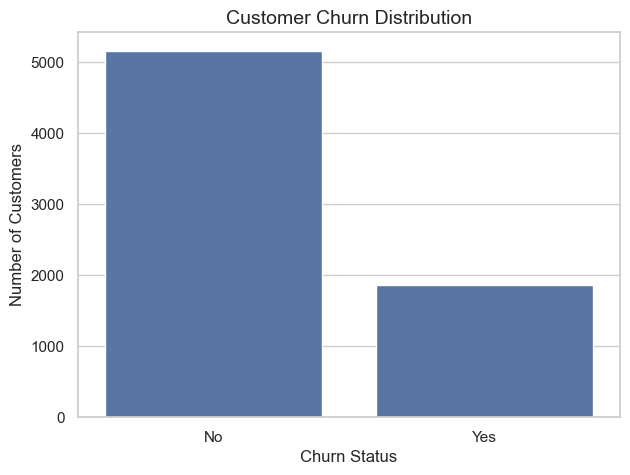

In [12]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution", fontsize=14)
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

In [13]:
churn_counts = df["Churn"].value_counts()

print("Customer counts:")
print(churn_counts)

print("\nChurn percentage:")
print(round((df["Churn"] == "Yes").mean() * 100, 2), "%")

Customer counts:
Churn
No     5163
Yes    1869
Name: count, dtype: int64

Churn percentage:
26.58 %


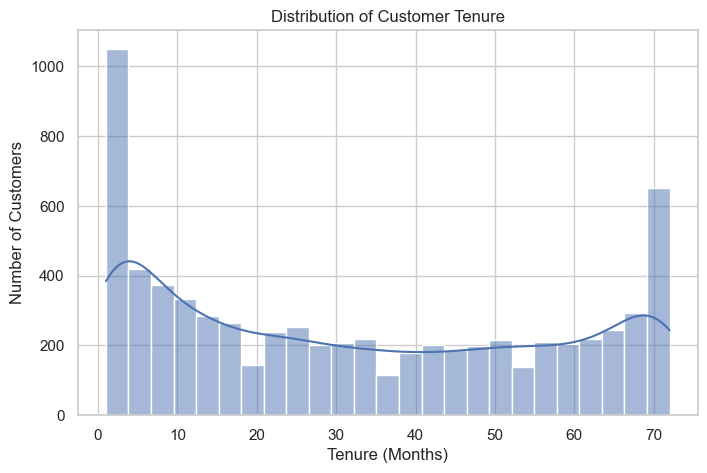

In [14]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="tenure", bins=25, kde=True)

plt.title("Distribution of Customer Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()

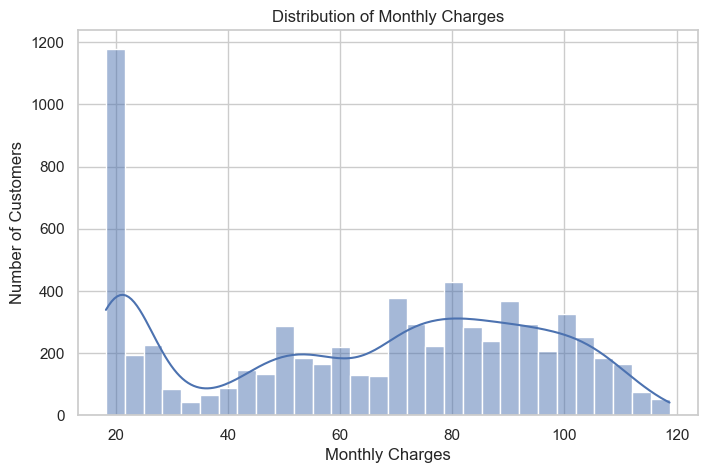

In [15]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="MonthlyCharges", bins=30, kde=True)

plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")

plt.show()

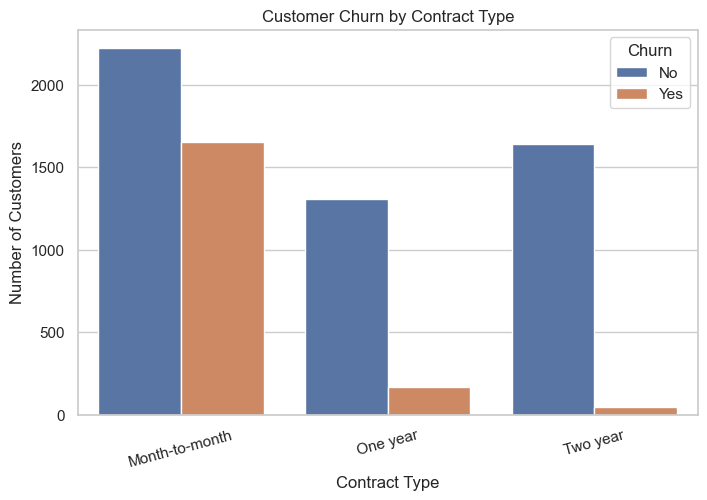

In [16]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Contract", hue="Churn")

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.xticks(rotation=15)
plt.show()

In [17]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.72  11.28
Two year        97.15   2.85


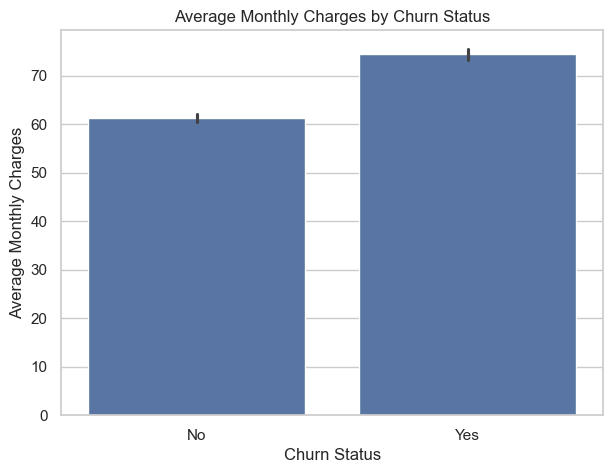

In [18]:
plt.figure(figsize=(7, 5))

sns.barplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Average Monthly Charges by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Average Monthly Charges")

plt.show()

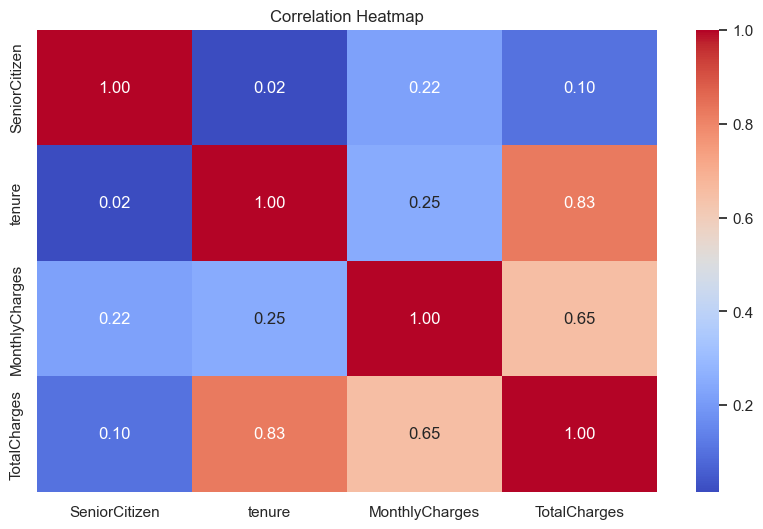

In [19]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(10, 6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [20]:
# Overall churn percentage
churn_rate = (df["Churn"] == "Yes").mean() * 100

print("Overall churn rate:", round(churn_rate, 2), "%")

# Average tenure by churn status
print("\nAverage tenure:")
print(df.groupby("Churn")["tenure"].mean().round(2))

# Average monthly charges by churn status
print("\nAverage monthly charges:")
print(df.groupby("Churn")["MonthlyCharges"].mean().round(2))

# Churn rate by contract type
print("\nChurn rate by contract type:")
contract_rates = (
    df.groupby("Contract")["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
)
print(contract_rates.round(2))

Overall churn rate: 26.58 %

Average tenure:
Churn
No     37.65
Yes    17.98
Name: tenure, dtype: float64

Average monthly charges:
Churn
No     61.31
Yes    74.44
Name: MonthlyCharges, dtype: float64

Churn rate by contract type:
Contract
Month-to-month    42.71
One year          11.28
Two year           2.85
Name: Churn, dtype: float64


In [ ]:
# Project Conclusion

## Key Findings
- Analyzed customer churn patterns using Python.
- Examined customer tenure and monthly charges.
- Compared churn across different contract types.
- Used a correlation heatmap to explore numerical relationships.

## Business Recommendations
- Investigate why customers on high-churn contract types leave.
- Review the experiences of newer customers.
- Evaluate pricing and customer retention strategies.

## Tools Used
- Python
- Pandas
- Matplotlib
- Seaborn

## Conclusion
Exploratory Data Analysis helped identify patterns in customer
behavior and provided insights that can support customer
retention decisions.

In [ ]:
### Exploratory Data Analysis of Customer Churn

*Tools: Python, Pandas, Matplotlib, Seaborn · October 2026*

- Performed exploratory data analysis on a telecommunications customer dataset containing approximately 7,043 records and 21 columns before cleaning.
- Cleaned data, handled missing values, and examined numerical statistics and customer behavior.
- Created visualizations including histograms, bar charts, and a correlation heatmap to explore churn patterns.
- Summarized findings and business recommendations in a Jupyter Notebook.

GitHub: [Add your repository link after publishing]